# Duka Electronics Board Report — H1 2026
**Engagement 2 · Visual Storytelling for the Board**

---

## Storyboard

| Element | Detail |
|---------|--------|
| **Audience** | Duka Electronics board members — non-technical, time-constrained, reading on mobile devices before the meeting |
| **Decision** | Where to focus sales and marketing investment in H2 2026 to maximise revenue |
| **Big Idea** | H1 revenue rests on Nairobi and laptops, and momentum faded after April, so H2 should defend the branches that slipped (Mombasa, Nakuru) while protecting laptop sales |
| **SCR (Situation)** | Duka Electronics earned KES 71.8M from 1,000 orders in H1 2026 |
| **SCR (Complication)** | Nairobi gives 36% of revenue and laptops 58%. Revenue peaked in April (KES 13.5M) and fell to KES 10.9M by June; Mombasa and Nakuru earned about a quarter less in Q2 than in Q1 |
| **SCR (Resolution)** | Run a recovery plan for Mombasa and Nakuru, protect laptop stock and promotions, and trial upselling on phone orders (highest value per order) |

---
## Setup — Imports and Data Loading

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.gridspec import GridSpec

# Ensure figures folder exists
os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Global style settings
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 80,
})

# Brand palette — single accent colour, neutral fills
ACCENT   = "#1565C0"   # Duka blue
POSITIVE = "#2E7D32"   # growth green
WARNING  = "#C62828"   # risk red
NEUTRAL  = "#90A4AE"   # grey fill for non-highlighted bars
BG       = "#FAFAFA"

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load and prepare data
df = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])

# Derived columns
df["revenue"]     = df["quantity"] * df["unit_price"]
df["month"]       = df["order_date"].dt.month
df["month_name"]  = df["order_date"].dt.strftime("%b")
df["week"]        = df["order_date"].dt.isocalendar().week.astype(int)

# Month order helper
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

print(f"Rows: {len(df):,}  |  Date range: {df['order_date'].min().date()} → {df['order_date'].max().date()}")
print(f"Total H1 Revenue: KES {df['revenue'].sum():,.0f}")
df.head(3)

Rows: 1,000  |  Date range: 2026-01-01 → 2026-06-29
Total H1 Revenue: KES 71,792,500


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,month_name,week
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000,6,Jun,23
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000,2,Feb,6
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000,1,Jan,2


---
## Chart 1 — Monthly Revenue Trend
**Insight title calculated in code below.**

Insight: Apr was the strongest month (KES 13.5M); Jun the weakest


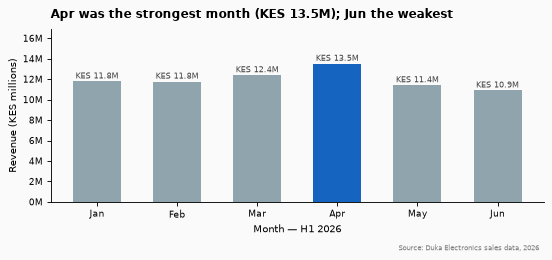

Saved → figures/chart1_monthly_revenue.png


In [3]:
# Monthly revenue aggregation
monthly = (
    df.groupby("month")["revenue"].sum()
    .reindex(range(1, 7))
    .reset_index()
)
monthly["month_name"] = ["Jan","Feb","Mar","Apr","May","Jun"]

# Calculate insight dynamically
peak_month   = monthly.loc[monthly["revenue"].idxmax(), "month_name"]
peak_rev     = monthly["revenue"].max()
lowest_month = monthly.loc[monthly["revenue"].idxmin(), "month_name"]
lowest_rev   = monthly["revenue"].min()

insight_title_1 = f"{peak_month} was the strongest month (KES {peak_rev/1e6:.1f}M); {lowest_month} the weakest"
print("Insight:", insight_title_1)

fig, ax = plt.subplots(figsize=(7, 3.5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

bars = ax.bar(
    monthly["month_name"],
    monthly["revenue"] / 1e6,
    color=[ACCENT if m == peak_month else NEUTRAL for m in monthly["month_name"]],
    width=0.6,
    edgecolor="none",
)

# Value labels on bars
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"KES {bar.get_height():.1f}M",
        ha="center", va="bottom", fontsize=7, color="#424242"
    )

ax.set_title(insight_title_1, pad=10, loc="left")
ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("Month — H1 2026")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.set_ylim(0, monthly["revenue"].max() / 1e6 * 1.25)
ax.text(0.99, -0.28, "Source: Duka Electronics sales data, 2026",
        transform=ax.transAxes, ha="right", fontsize=6.5, color="grey")

plt.tight_layout()
plt.savefig("figures/chart1_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/chart1_monthly_revenue.png")

---
## Chart 2 — Revenue by Branch
**Insight title calculated in code below.**

Insight: Nairobi accounts for 36% of H1 revenue — concentration risk


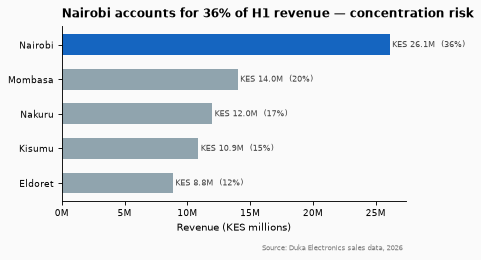

Saved → figures/chart2_branch_revenue.png


In [4]:
branch_rev = df.groupby("branch")["revenue"].sum().sort_values(ascending=True)
total_rev  = branch_rev.sum()

top_branch      = branch_rev.idxmax()
top_branch_pct  = branch_rev.max() / total_rev * 100
insight_title_2 = f"{top_branch} accounts for {top_branch_pct:.0f}% of H1 revenue — concentration risk"
print("Insight:", insight_title_2)

fig, ax = plt.subplots(figsize=(6, 3.5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

colours = [ACCENT if b == top_branch else NEUTRAL for b in branch_rev.index]
bars = ax.barh(branch_rev.index, branch_rev.values / 1e6, color=colours,
               edgecolor="none", height=0.6)

for bar, val in zip(bars, branch_rev.values):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"KES {val/1e6:.1f}M  ({val/total_rev*100:.0f}%)",
            va="center", fontsize=7.5, color="#424242")

ax.set_title(insight_title_2, pad=8, loc="left")
ax.set_xlabel("Revenue (KES millions)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.text(0.99, -0.28, "Source: Duka Electronics sales data, 2026",
        transform=ax.transAxes, ha="right", fontsize=6.5, color="grey")

plt.tight_layout()
plt.savefig("figures/chart2_branch_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/chart2_branch_revenue.png")

---
## Chart 3 — Revenue by Product Category
**Insight title calculated in code below.**

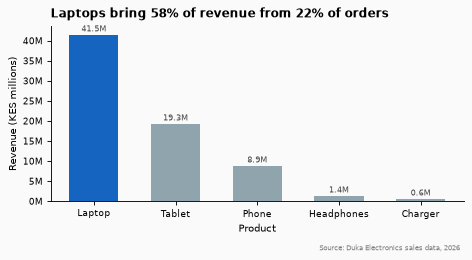

Saved → figures/chart3_product_revenue.png


In [5]:
product_rev = df.groupby("product")["revenue"].sum().sort_values(ascending=False)
top_product     = product_rev.idxmax()
top_product_pct = product_rev.max() / product_rev.sum() * 100

order_share = df["product"].value_counts(normalize=True)[top_product] * 100
insight_title_3 = f"{top_product}s bring {top_product_pct:.0f}% of revenue from {order_share:.0f}% of orders"

fig, ax = plt.subplots(figsize=(6, 3.5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

colours = [ACCENT if p == top_product else NEUTRAL for p in product_rev.index]
bars = ax.bar(product_rev.index, product_rev.values / 1e6, color=colours,
              edgecolor="none", width=0.6)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"{bar.get_height():.1f}M", ha="center", va="bottom", fontsize=7.5, color="#424242")

ax.set_title(insight_title_3, pad=8, loc="left")
ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("Product")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))
ax.text(0.99, -0.28, "Source: Duka Electronics sales data, 2026",
        transform=ax.transAxes, ha="right", fontsize=6.5, color="grey")

plt.tight_layout()
plt.savefig("figures/chart3_product_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/chart3_product_revenue.png")

In [6]:
df["half"] = np.where(df["month"] <= 3, "Q1", "Q2")
bq = df.pivot_table(index="branch", columns="half", values="revenue", aggfunc="sum")
bq["change_pct"] = (bq["Q2"] / bq["Q1"] - 1) * 100
print(bq.sort_values("change_pct").round(1))

half           Q1        Q2  change_pct
branch                                 
Nakuru    6900200   5070200       -26.5
Mombasa   8023100   5980600       -25.5
Nairobi  12484700  13621400         9.1
Kisumu    5008900   5859200        17.0
Eldoret   3538500   5305700        49.9


---
## Chart 4 — Channel Revenue Comparison
**Insight title calculated in code below.**

Insight: Phone order has the highest revenue per order (KES 79,576) — prioritise channel mix


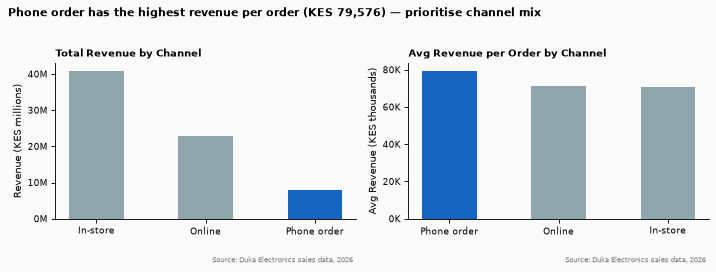

Saved → figures/chart4_channel_revenue.png


In [7]:
channel_rev     = df.groupby("channel")["revenue"].sum()
channel_orders  = df.groupby("channel")["order_id"].count()
channel_avg_rev = (channel_rev / channel_orders).sort_values(ascending=False)

top_channel     = channel_avg_rev.idxmax()
top_avg         = channel_avg_rev.max()
insight_title_4 = f"{top_channel} has the highest revenue per order (KES {top_avg:,.0f}) — prioritise channel mix"
print("Insight:", insight_title_4)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
fig.patch.set_facecolor(BG)

# Left: total revenue by channel
ax1 = axes[0]
ax1.set_facecolor(BG)
colours = [ACCENT if c == top_channel else NEUTRAL for c in channel_rev.index]
ax1.bar(channel_rev.index, channel_rev.values / 1e6, color=colours, edgecolor="none", width=0.5)
ax1.set_title("Total Revenue by Channel", loc="left", fontsize=9, fontweight="bold")
ax1.set_ylabel("Revenue (KES millions)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}M"))

# Right: avg revenue per order
ax2 = axes[1]
ax2.set_facecolor(BG)
colours2 = [ACCENT if c == top_channel else NEUTRAL for c in channel_avg_rev.index]
ax2.bar(channel_avg_rev.index, channel_avg_rev.values / 1e3, color=colours2, edgecolor="none", width=0.5)
ax2.set_title("Avg Revenue per Order by Channel", loc="left", fontsize=9, fontweight="bold")
ax2.set_ylabel("Avg Revenue (KES thousands)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}K"))

for ax in axes:
    ax.spines[["top","right"]].set_visible(False)
    ax.text(0.99, -0.28, "Source: Duka Electronics sales data, 2026",
            transform=ax.transAxes, ha="right", fontsize=6.5, color="grey")

fig.suptitle(insight_title_4, fontsize=10, fontweight="bold", x=0.01, ha="left", y=1.02)
plt.tight_layout()
plt.savefig("figures/chart4_channel_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/chart4_channel_revenue.png")

---
## Full One-Page Board Report
All four charts assembled into a single-page layout and exported to `reports/duka_board_report.png`.

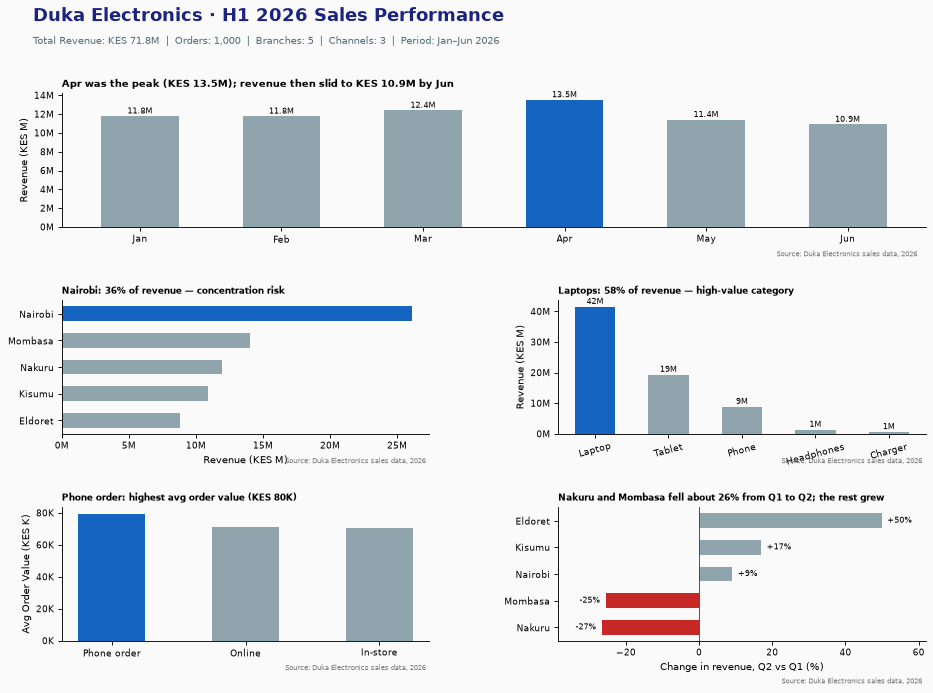

Board report saved → reports/duka_board_report.png


In [8]:
# ── Recompute all aggregations for the board layout ──────────────────────────
monthly_rev = (
    df.groupby("month")["revenue"].sum()
    .reindex(range(1, 7)).values
)
month_labels = ["Jan","Feb","Mar","Apr","May","Jun"]

branch_rev_s   = df.groupby("branch")["revenue"].sum().sort_values()
product_rev_s  = df.groupby("product")["revenue"].sum().sort_values(ascending=False)
channel_rev_s  = df.groupby("channel")["revenue"].sum()
channel_ord_s  = df.groupby("channel")["order_id"].count()
ch_avg_s       = (channel_rev_s / channel_ord_s).sort_values(ascending=False)

# Insight strings
total_rev_m  = df["revenue"].sum() / 1e6
total_orders = len(df)

peak_m   = month_labels[int(np.argmax(monthly_rev))]
top_br   = branch_rev_s.idxmax()
top_br_p = branch_rev_s.max() / branch_rev_s.sum() * 100
top_pr   = product_rev_s.idxmax()
top_pr_p = product_rev_s.max() / product_rev_s.sum() * 100
top_ch   = ch_avg_s.idxmax()
top_ch_a = ch_avg_s.max()

# ── Build figure ──────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 9), facecolor=BG)
gs  = GridSpec(3, 2, figure=fig,
               hspace=0.55, wspace=0.35,
               top=0.83, bottom=0.07, left=0.07, right=0.97)

# ── Header ───────────────────────────────────────────────────────────────────
fig.text(0.04, 0.95,
         "Duka Electronics · H1 2026 Sales Performance",
         fontsize=16, fontweight="bold", color="#1A237E", va="top")
fig.text(0.04, 0.91,
         f"Total Revenue: KES {total_rev_m:.1f}M  |  Orders: {total_orders:,}  |  "
         f"Branches: 5  |  Channels: 3  |  Period: Jan–Jun 2026",
         fontsize=9, color="#546E7A", va="top")

SOURCE = "Source: Duka Electronics sales data, 2026"

def style_ax(ax, y=-0.22):
    ax.spines[["top","right"]].set_visible(False)
    ax.set_facecolor(BG)
    ax.text(0.99, y, SOURCE, transform=ax.transAxes,
            ha="right", fontsize=6, color="grey")

# ── Chart 1: Monthly Revenue Trend ───────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
bar_colours = [ACCENT if m == peak_m else NEUTRAL for m in month_labels]
bars1 = ax1.bar(month_labels, monthly_rev / 1e6, color=bar_colours,
                edgecolor="none", width=0.55)
for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.08,
             f"{bar.get_height():.1f}M", ha="center", va="bottom", fontsize=7)
ax1.set_title(f"{peak_m} was the peak (KES {monthly_rev.max()/1e6:.1f}M); revenue then slid to KES {monthly_rev[-1]/1e6:.1f}M by {month_labels[-1]}",
              loc="left", fontsize=9, fontweight="bold")
ax1.set_ylabel("Revenue (KES M)")
ax1.yaxis.set_major_locator(mticker.MultipleLocator(2))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
style_ax(ax1)

# ── Chart 2: Branch Revenue ───────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
br_colours = [ACCENT if b == top_br else NEUTRAL for b in branch_rev_s.index]
ax2.barh(branch_rev_s.index, branch_rev_s.values / 1e6, color=br_colours,
         edgecolor="none", height=0.55)
ax2.set_title(f"{top_br}: {top_br_p:.0f}% of revenue — concentration risk",
              loc="left", fontsize=8.5, fontweight="bold")
ax2.set_xlabel("Revenue (KES M)")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
style_ax(ax2)

# ── Chart 3: Product Revenue ──────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 1])
pr_colours = [ACCENT if p == top_pr else NEUTRAL for p in product_rev_s.index]
ax3.bar(product_rev_s.index, product_rev_s.values / 1e6, color=pr_colours,
        edgecolor="none", width=0.55)
for i, (p, v) in enumerate(product_rev_s.items()):
    ax3.text(i, v/1e6 + 0.3, f"{v/1e6:.0f}M", ha="center", va="bottom", fontsize=7)
ax3.set_title(f"Laptops: {top_pr_p:.0f}% of revenue — high-value category",
              loc="left", fontsize=8.5, fontweight="bold")
ax3.set_ylabel("Revenue (KES M)")
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
ax3.tick_params(axis="x", rotation=15)
style_ax(ax3)

# ── Chart 4: Channel avg revenue per order ───────────────────────────────────
ax4 = fig.add_subplot(gs[2, 0])
ch_colours = [ACCENT if c == top_ch else NEUTRAL for c in ch_avg_s.index]
ax4.bar(ch_avg_s.index, ch_avg_s.values / 1e3, color=ch_colours,
        edgecolor="none", width=0.5)
ax4.set_title(f"{top_ch}: highest avg order value (KES {top_ch_a/1e3:.0f}K)",
              loc="left", fontsize=8.5, fontweight="bold")
ax4.set_ylabel("Avg Order Value (KES K)")
ax4.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}K"))
style_ax(ax4)

# ── Chart 5: Q1 → Q2 revenue change by branch ──────────────────────────────
df["half"] = np.where(df["month"] <= 3, "Q1", "Q2")
bq = df.pivot_table(index="branch", columns="half", values="revenue", aggfunc="sum")
chg = ((bq["Q2"] / bq["Q1"] - 1) * 100).sort_values()

n_fell    = int((chg < 0).sum())
fell_list = " and ".join(chg.index[:n_fell])
fell_avg  = abs(chg[chg < 0].mean())

ax5 = fig.add_subplot(gs[2, 1])
ax5.barh(chg.index, chg.values,
         color=[WARNING if v < 0 else NEUTRAL for v in chg.values],
         edgecolor="none", height=0.55)
for i, v in enumerate(chg.values):
    ax5.text(v + (1.5 if v >= 0 else -1.5), i, f"{v:+.0f}%",
             va="center", ha="left" if v >= 0 else "right", fontsize=7)
ax5.axvline(0, color="#424242", linewidth=0.8)
ax5.set_xlim(chg.min() - 12, chg.max() + 12)
ax5.set_title(f"{fell_list} fell about {fell_avg:.0f}% from Q1 to Q2; the rest grew",
              loc="left", fontsize=8.5, fontweight="bold")
ax5.set_xlabel("Change in revenue, Q2 vs Q1 (%)")
ax5.set_ylabel("")
ax5.spines[["top","right"]].set_visible(False)
ax5.set_facecolor(BG)
ax5.text(0.99, -0.32, SOURCE, transform=ax5.transAxes, ha="right", fontsize=6, color="grey")

plt.savefig("reports/duka_board_report.png", dpi=180, bbox_inches="tight",
            facecolor=BG)
plt.show()
print("Board report saved → reports/duka_board_report.png")

---
## Chart Makeover — Before & After
We take a plain default pandas bar chart of branch revenue (the 'before') and redesign it with decluttering, insight title, purposeful colour and labelled units (the 'after').

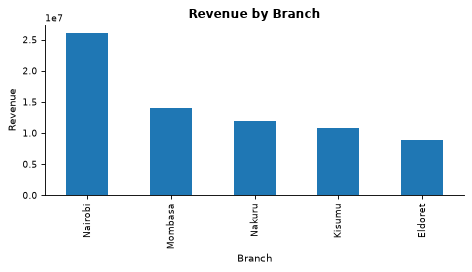

Saved → figures/before.png


In [9]:
# ── BEFORE ─────────────────────────────────────────────────────────────────
# Deliberately minimal — vanilla matplotlib defaults, no design decisions
branch_rev_sorted = df.groupby("branch")["revenue"].sum().sort_values(ascending=False)

fig_b, ax_b = plt.subplots(figsize=(6, 3.5))
branch_rev_sorted.plot(kind="bar", ax=ax_b)   # default pandas colours, no labels
ax_b.set_title("Revenue by Branch")            # generic title
ax_b.set_xlabel("Branch")
ax_b.set_ylabel("Revenue")

plt.tight_layout()
plt.savefig("figures/before.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/before.png")

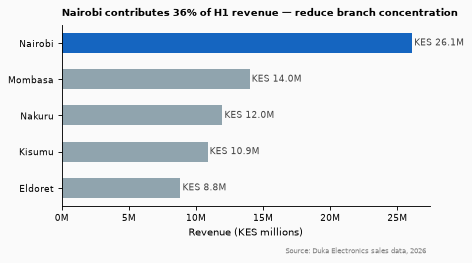

Saved → figures/after.png


In [10]:
# ── AFTER ──────────────────────────────────────────────────────────────────
# Design changes applied:
# 1. Insight title instead of generic label
# 2. Single-accent colour (blue) on the highest bar; neutral grey for others
# 3. Top & right spines removed (declutter)
# 4. Revenue in millions on y-axis (units labelled)
# 5. Horizontal bar orientation (easier to read branch names)
# 6. Data labels on bars
# 7. Source line added

top_br_after = branch_rev_sorted.idxmax()
pct_top      = branch_rev_sorted.max() / branch_rev_sorted.sum() * 100
insight      = f"{top_br_after} contributes {pct_top:.0f}% of H1 revenue — reduce branch concentration"

fig_a, ax_a = plt.subplots(figsize=(6, 3.5))
fig_a.patch.set_facecolor(BG)
ax_a.set_facecolor(BG)

sorted_asc = branch_rev_sorted.sort_values()   # horizontal bars read bottom-to-top
colours = [ACCENT if b == top_br_after else NEUTRAL for b in sorted_asc.index]
bars = ax_a.barh(sorted_asc.index, sorted_asc.values / 1e6,
                 color=colours, edgecolor="none", height=0.55)

for bar in bars:
    ax_a.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
              f"KES {bar.get_width():.1f}M", va="center", fontsize=8, color="#424242")

ax_a.set_title(insight, pad=8, loc="left", fontsize=9, fontweight="bold")
ax_a.set_xlabel("Revenue (KES millions)")
ax_a.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.0f}M"))
ax_a.spines[["top","right"]].set_visible(False)
ax_a.text(0.99, -0.26, "Source: Duka Electronics sales data, 2026",
          transform=ax_a.transAxes, ha="right", fontsize=6.5, color="grey")

plt.tight_layout()
plt.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/after.png")

### Design Change Explanation

![Before](figures/before.png) ![After](figures/after.png)

| # | Change | Why |
|---|--------|-----|
| 1 | Generic title replaced by an **insight title** | The reader gets the conclusion before studying the bars |
| 2 | **One accent colour** on Nairobi, grey on the rest | The eye goes straight to the key bar; no legend needed |
| 3 | **Top and right borders removed** | Less clutter; the data gets the attention |
| 4 | Axis shown in **KES millions** and labelled | Units are explicit, so the numbers cannot be misread |
| 5 | **Horizontal bars, largest on top** | Branch names are easier to read, especially on a phone |
| 6 | **Data labels** on each bar | Values can be read without tracing to the axis |
| 7 | **Source line** added | The reader can see where the numbers come from |

---
## Board Summary 

Duka Electronics earned KES 71.8 million from 1,000 orders in the first half of 2026. Nairobi brought in 36% of it, so the business leans heavily on one branch. Laptops are the engine: 58% of revenue from only 22% of orders. Revenue peaked in April at KES 13.5 million and slid to KES 10.9 million by June. Mombasa and Nakuru each earned about a quarter less in April–June than in January–March, while Nairobi, Kisumu and Eldoret grew. Online and in-store orders are worth about the same (roughly KES 71,000 each); phone orders are worth more (KES 80,000) but are only one order in ten. For the second half we recommend: a recovery plan for Mombasa and Nakuru, protecting laptop stock and promotions, and a trial of phone-order upselling. These figures cover January–June only, so April's peak may be a short swing rather than a seasonal pattern.